# General

In [ ]:
import os
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

DATA_ROOT = Path(os.environ.get('DL_DATA_DIR', '../../.lab-data')).resolve()
MODEL_DIR = DATA_ROOT / 'models' / 'lab7'
from model_io import save_model, load_model

# Horses and humans: validation

## Data

In [2]:
SIZE = 300

train_dir = DATA_ROOT / 'horse-or-human'
validation_dir = DATA_ROOT / 'validation-horse-or-human'
classes = ['horses', 'humans']
for subset in [train_dir, validation_dir]:
    for label in classes:
        files = sorted((subset / label).glob('*.png'))
        print(subset.name, label, len(files), [p.name for p in files[:5]])

horse-or-human horses 500 ['horse01-0.png', 'horse01-1.png', 'horse01-2.png', 'horse01-3.png', 'horse01-4.png']
horse-or-human humans 527 ['human01-00.png', 'human01-01.png', 'human01-02.png', 'human01-03.png', 'human01-04.png']
validation-horse-or-human horses 128 ['horse1-000.png', 'horse1-105.png', 'horse1-122.png', 'horse1-127.png', 'horse1-170.png']
validation-horse-or-human humans 128 ['valhuman01-00.png', 'valhuman01-01.png', 'valhuman01-02.png', 'valhuman01-03.png', 'valhuman01-04.png']


In [ ]:
def preview_images(directory, classes):
    fig, axs = plt.subplots(2, 4, figsize=(12, 6))
    for row, label in enumerate(classes):
        files = sorted((directory / label).glob('*'))[:4]
        for ax, path in zip(axs[row], files):
            ax.imshow(Image.open(path))
            ax.set_title(label)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

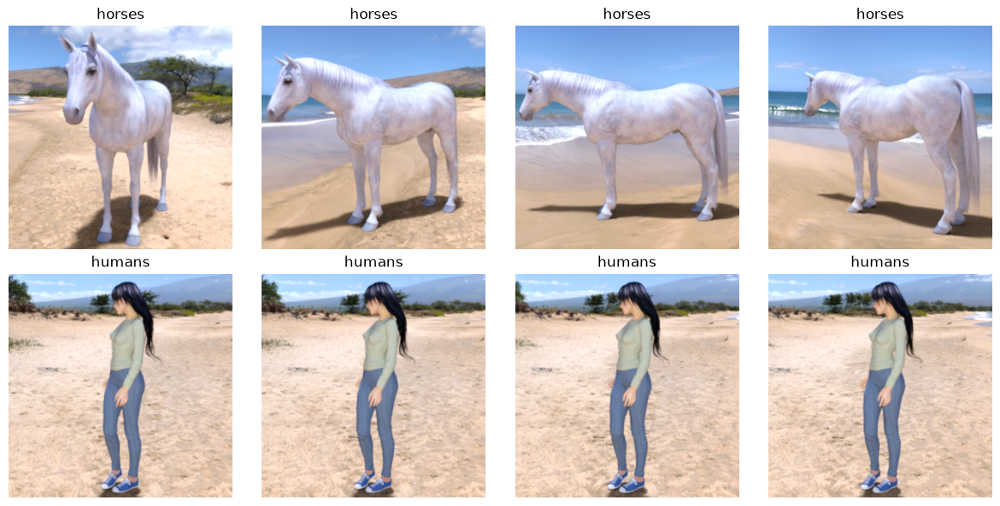

In [3]:
preview_images(train_dir, classes)

In [ ]:
def make_generator(directory, classes, size, batch_size=32, shuffle=False):
    return ImageDataGenerator(rescale=1./255).flow_from_directory(
        directory, target_size=(size, size), batch_size=batch_size,
        classes=classes, class_mode='binary', shuffle=shuffle, seed=42)

In [4]:
train_generator = make_generator(train_dir, classes, SIZE, shuffle=True)
validation_generator = make_generator(validation_dir, classes, SIZE)
print('Labels:', train_generator.class_indices)

Found 1027 images belonging to 2 classes.


Found 256 images belonging to 2 classes.


Labels: {'horses': 0, 'humans': 1}


## Model

In [ ]:
def build_horse_model(size, blocks):
    model = keras.Sequential([layers.Input(shape=(size, size, 3))])
    for filters in [16, 32, 64, 64, 64][:blocks]:
        model.add(layers.Conv2D(filters, 3, activation='relu'))
        model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

In [6]:
model = build_horse_model(SIZE, 5)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 298, 298, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 149, 149, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 147, 147, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 73, 73, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 71, 71, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 35, 35, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 33, 33, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,606,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,704,097 (6.50 MB)

 Trainable params: 1,704,097 (6.50 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [ ]:
def plot_history(history, name):
    history = pd.DataFrame(history)
    epochs = np.arange(1, len(history) + 1)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axs, ['accuracy', 'loss']):
        ax.plot(epochs, history[metric], label='Training')
        if f'val_{metric}' in history:
            ax.plot(epochs, history[f'val_{metric}'], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric.capitalize())
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    fig.savefig(f'results/{name}_history.png', dpi=150)
    plt.show()

Epoch 1/15


33/33 - 23s - 704ms/step - accuracy: 0.6621 - loss: 0.6414


Epoch 2/15


33/33 - 6s - 194ms/step - accuracy: 0.8608 - loss: 0.3825


Epoch 3/15


33/33 - 6s - 184ms/step - accuracy: 0.9172 - loss: 0.2172


... (20 outputs left out)

Epoch 14/15


33/33 - 6s - 185ms/step - accuracy: 1.0000 - loss: 2.4288e-04


Epoch 15/15


33/33 - 6s - 180ms/step - accuracy: 1.0000 - loss: 9.1808e-05


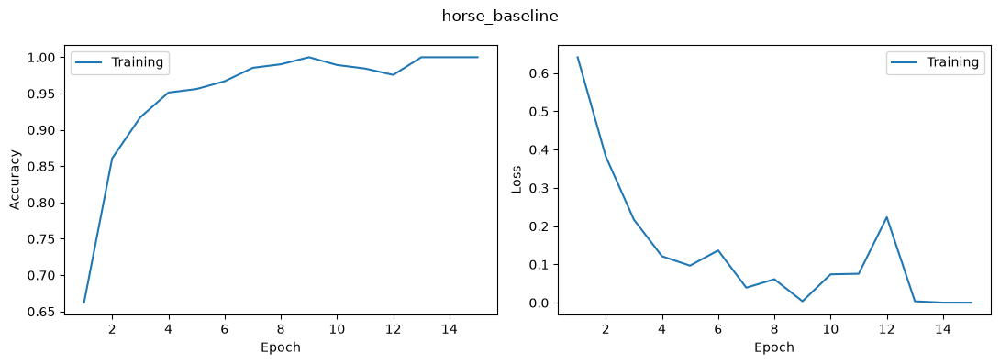

In [8]:
# First run the original experiment without validation.
start = time.perf_counter()
history = model.fit(train_generator, epochs=15, verbose=2)
baseline_seconds = time.perf_counter() - start
baseline_history = pd.DataFrame(history.history)
baseline_history.to_csv('results/horse_baseline_history.csv', index=False)
plot_history(history.history, 'horse_baseline')
model.save(MODEL_DIR / 'horse_baseline.keras')
save_model(model, 'models/horse_baseline')
baseline_loss, baseline_accuracy = model.evaluate(validation_generator, verbose=0)

In [9]:
# Restart with the same initialization and add automatic validation.
keras.backend.clear_session()
keras.utils.set_random_seed(42)
model = build_horse_model(SIZE, 5)
train_generator.reset()
start = time.perf_counter()
history = model.fit(train_generator, validation_data=validation_generator, epochs=15, verbose=2)
training_seconds = time.perf_counter() - start

Epoch 1/15


33/33 - 12s - 364ms/step - accuracy: 0.5755 - loss: 0.7318 - val_accuracy: 0.6094 - val_loss: 0.6146


Epoch 2/15


33/33 - 7s - 209ms/step - accuracy: 0.8705 - loss: 0.3371 - val_accuracy: 0.7617 - val_loss: 1.1719


Epoch 3/15


33/33 - 7s - 207ms/step - accuracy: 0.9163 - loss: 0.2665 - val_accuracy: 0.8398 - val_loss: 1.0235


... (20 outputs left out)

Epoch 14/15


33/33 - 6s - 193ms/step - accuracy: 1.0000 - loss: 3.7241e-05 - val_accuracy: 0.8164 - val_loss: 3.5654


Epoch 15/15


33/33 - 7s - 204ms/step - accuracy: 0.9718 - loss: 0.3522 - val_accuracy: 0.7539 - val_loss: 1.9620


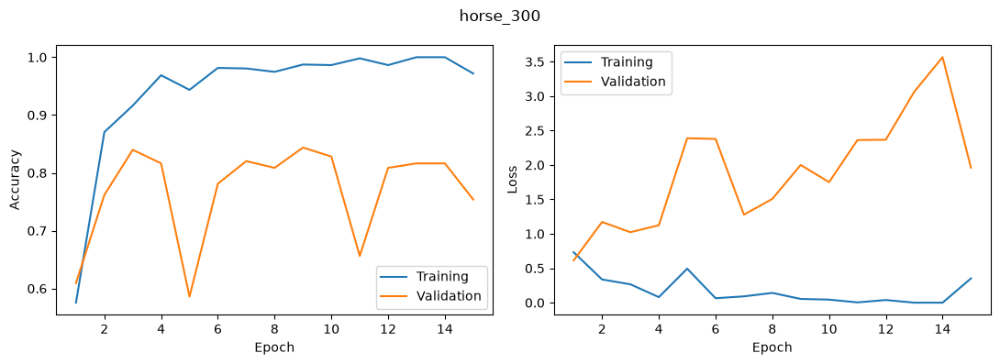

In [10]:
pd.DataFrame(history.history).to_csv('results/horse_300_history.csv', index=False)
plot_history(history.history, 'horse_300')

## Results

In [11]:
loss, accuracy = model.evaluate(validation_generator, verbose=0)
result = {'size': SIZE, 'parameters': model.count_params(), 'epochs': len(history.epoch),
          'seconds': training_seconds, 'train_accuracy': history.history['accuracy'][-1],
          'validation_accuracy': accuracy, 'validation_loss': loss}
display(pd.DataFrame([result]))
Path(f'results/horse_{SIZE}_metrics.json').write_text(json.dumps(result, indent=2))

,size,parameters,epochs,seconds,train_accuracy,validation_accuracy,validation_loss
0,300,1704097,15,106.656458,0.971762,0.753906,1.961971


209

In [12]:
baseline = {'size': SIZE, 'seconds': baseline_seconds, 'validation_loss': baseline_loss,
            'validation_accuracy': baseline_accuracy,
            'train_accuracy': float(baseline_history['accuracy'].iloc[-1])}
Path('results/horse_baseline_metrics.json').write_text(json.dumps(baseline, indent=2))
display(pd.DataFrame([baseline, result]))

,size,seconds,validation_loss,validation_accuracy,train_accuracy,parameters,epochs
0,300,106.643549,3.173845,0.828125,1.000000,NaN,NaN
1,300,106.656458,1.961971,0.753906,0.971762,1704097.0,15.0


## Saving

In [3]:
model.save(MODEL_DIR / f'horse_{SIZE}.keras')
save_model(model, 'models/horse_300')

## New images

In [ ]:
def predict_horses(models, size):
    classes = ['horses', 'humans']
    image_dir = Path('horse-images')
    manifest = pd.DataFrame(json.loads((image_dir / 'manifest.json').read_text()))
    images = []
    for filename in manifest['file']:
        image = keras.utils.load_img(image_dir / filename, target_size=(size, size))
        images.append(keras.utils.img_to_array(image) / 255.0)
    images = np.array(images)
    rows = []
    fig, axs = plt.subplots(len(models), len(images), figsize=(20, 3 * len(models)), squeeze=False)
    for row, (name, model) in enumerate(models.items()):
        probabilities = model.predict(images, batch_size=8, verbose=0).ravel()
        for i, probability in enumerate(probabilities):
            prediction = classes[int(probability >= 0.5)]
            expected = manifest.iloc[i]['class']
            correct = prediction == expected if expected != 'ambiguous' else None
            rows.append({'model': name, 'file': manifest.iloc[i]['file'], 'class': expected,
                         'category': manifest.iloc[i]['category'], 'prediction': prediction,
                         'human_probability': float(probability), 'correct': correct})
            axs[row, i].imshow(Image.open(image_dir / manifest.iloc[i]['file']))
            axs[row, i].set_title(f'{name}\n{expected} --> {prediction}', fontsize=8)
            axs[row, i].axis('off')
    plt.tight_layout()
    plt.show()
    new_results = pd.DataFrame(rows)
    display(new_results)
    new_results.to_csv(f'results/horse_{size}_external.csv', index=False)
    # A rider contains both classes, so it is shown without an accuracy label.
    return new_results

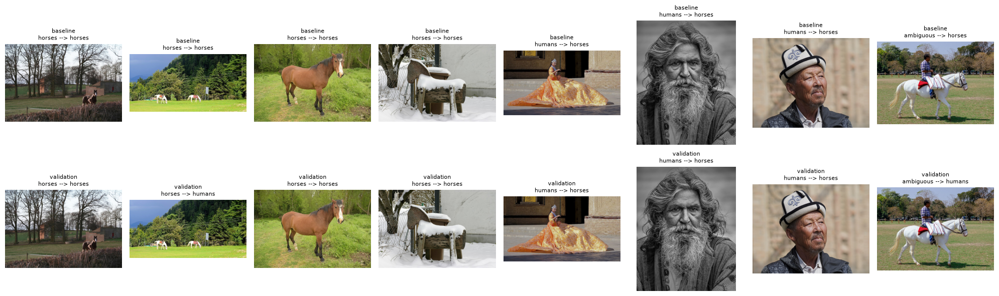

,model,file,class,category,prediction,human_probability,correct
0,baseline,horses_01.jpg,horses,ordinary,horses,7.929151e-36,True
1,baseline,horses_02.jpg,horses,white horse,horses,2.065370e-19,True
2,baseline,horses_03.jpg,horses,occluded legs,horses,2.286498e-17,True
3,baseline,horses_04.jpg,horses,toy,horses,1.599100e-21,True
4,baseline,humans_01.jpg,humans,long dress,horses,2.994978e-04,False
5,baseline,humans_02.jpg,humans,long hair,horses,1.843660e-28,False
6,baseline,humans_03.jpg,humans,hat,horses,4.159031e-02,False
7,baseline,ambiguous_01.jpg,ambiguous,horse and human,horses,1.113357e-03,None
8,validation,horses_01.jpg,horses,ordinary,horses,2.349531e-11,True
9,validation,horses_02.jpg,horses,white horse,humans,7.808008e-01,False


In [6]:
models = {'baseline': keras.models.load_model(MODEL_DIR / 'horse_baseline.keras'), 'validation': model}
horse_300_results = predict_horses(models, SIZE)

In [ ]:
del models, model
keras.backend.clear_session()

# Horses and humans: smaller images

## Data

In [4]:
SIZE = 150
train_generator = make_generator(train_dir, classes, SIZE, shuffle=True)
validation_generator = make_generator(validation_dir, classes, SIZE)

Found 1027 images belonging to 2 classes.


Found 256 images belonging to 2 classes.


Labels: {'horses': 0, 'humans': 1}


## Model

In [6]:
keras.utils.set_random_seed(42)
model = build_horse_model(SIZE, 3)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     9,470,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,494,561 (36.22 MB)

 Trainable params: 9,494,561 (36.22 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [8]:
start = time.perf_counter()
history = model.fit(train_generator, validation_data=validation_generator, epochs=15, verbose=2)
training_seconds = time.perf_counter() - start

Epoch 1/15


33/33 - 14s - 417ms/step - accuracy: 0.7449 - loss: 0.6572 - val_accuracy: 0.8203 - val_loss: 0.5669


Epoch 2/15


33/33 - 5s - 155ms/step - accuracy: 0.9484 - loss: 0.1439 - val_accuracy: 0.7305 - val_loss: 1.1636


Epoch 3/15


33/33 - 5s - 156ms/step - accuracy: 0.9552 - loss: 0.1319 - val_accuracy: 0.8320 - val_loss: 1.1391


... (20 outputs left out)

Epoch 14/15


33/33 - 5s - 150ms/step - accuracy: 1.0000 - loss: 3.2914e-04 - val_accuracy: 0.8242 - val_loss: 2.6063


Epoch 15/15


33/33 - 5s - 155ms/step - accuracy: 1.0000 - loss: 1.4388e-04 - val_accuracy: 0.8242 - val_loss: 3.0634


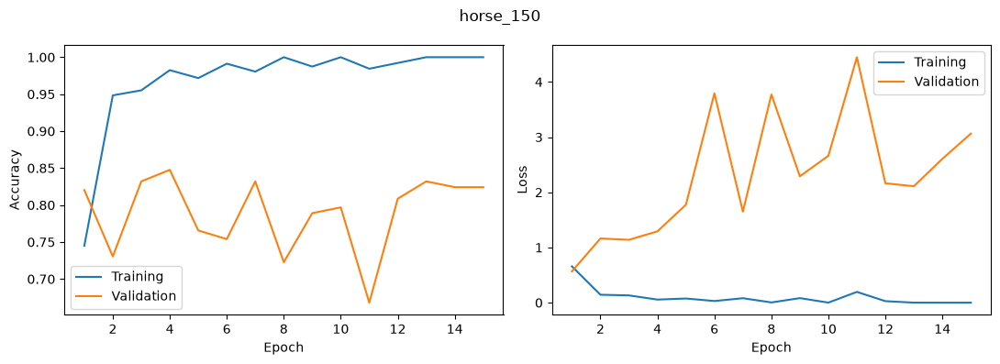

In [9]:
pd.DataFrame(history.history).to_csv('results/horse_150_history.csv', index=False)
plot_history(history.history, 'horse_150')

## Results

In [10]:
loss, accuracy = model.evaluate(validation_generator, verbose=0)
result = {'size': SIZE, 'parameters': model.count_params(), 'epochs': len(history.epoch),
          'seconds': training_seconds, 'train_accuracy': history.history['accuracy'][-1],
          'validation_accuracy': accuracy, 'validation_loss': loss}
display(pd.DataFrame([result]))
Path(f'results/horse_{SIZE}_metrics.json').write_text(json.dumps(result, indent=2))

,size,parameters,epochs,seconds,train_accuracy,validation_accuracy,validation_loss
0,150,9494561,15,84.751331,1.0,0.824219,3.06343


192

In [11]:
previous = json.loads(Path('results/horse_300_metrics.json').read_text())
comparison = pd.DataFrame([previous, result])
comparison.to_csv('results/horse_comparison.csv', index=False)
display(comparison)

,size,parameters,epochs,seconds,train_accuracy,validation_accuracy,validation_loss
0,300,1704097,15,106.656458,0.971762,0.753906,1.961971
1,150,9494561,15,84.751331,1.000000,0.824219,3.063430


## Saving

In [3]:
model.save(MODEL_DIR / f'horse_{SIZE}.keras')
save_model(model, 'models/horse_150')

## New images

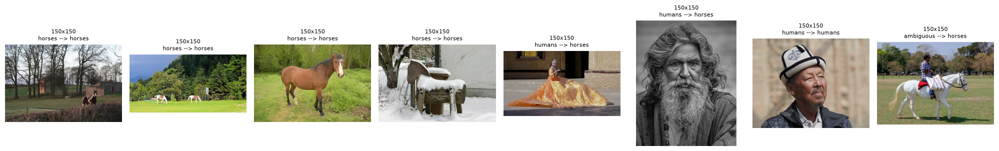

,model,file,class,category,prediction,human_probability,correct
0,150x150,horses_01.jpg,horses,ordinary,horses,4.173062e-30,True
1,150x150,horses_02.jpg,horses,white horse,horses,1.841213e-29,True
2,150x150,horses_03.jpg,horses,occluded legs,horses,1.444714e-17,True
3,150x150,horses_04.jpg,horses,toy,horses,1.556192e-15,True
4,150x150,humans_01.jpg,humans,long dress,horses,6.245881e-08,False
5,150x150,humans_02.jpg,humans,long hair,horses,6.225079e-16,False
6,150x150,humans_03.jpg,humans,hat,humans,1.000000e+00,True
7,150x150,ambiguous_01.jpg,ambiguous,horse and human,horses,3.569194e-13,None


In [15]:
horse_150_results = predict_horses({'150x150': model}, SIZE)

In [ ]:
del model
keras.backend.clear_session()

# Happy and sad

## Data

In [2]:
train_dir = DATA_ROOT / 'happy-sad' / 'data'
classes = ['happy', 'sad']
for label in classes:
    print(label, len(list((train_dir / label).glob('*.png'))))

happy 40
sad 40


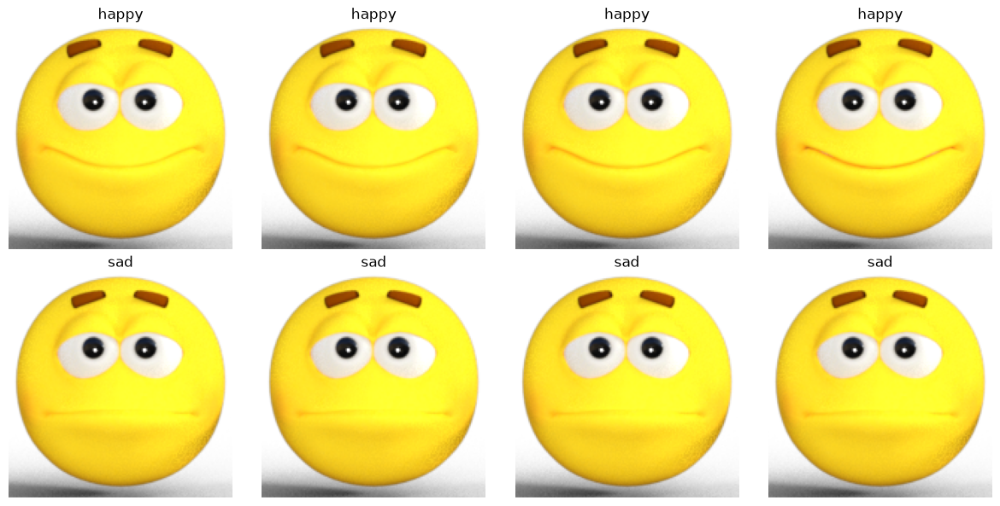

In [3]:
preview_images(train_dir, classes)

In [4]:
train_generator = make_generator(train_dir, classes, 150, batch_size=16, shuffle=True)

Found 80 images belonging to 2 classes.


## Model

In [5]:
keras.utils.set_random_seed(42)
model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Conv2D(16, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     9,470,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,494,561 (36.22 MB)

 Trainable params: 9,494,561 (36.22 MB)

 Non-trainable params: 0 (0.00 B)

## Training

In [6]:
class myCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        accuracy = (logs or {}).get('accuracy', 0)
        if accuracy >= 0.999:
            print('Reached 99.9% accuracy so cancelling training!')
            self.model.stop_training = True

In [7]:
history = model.fit(train_generator, epochs=14, callbacks=[myCallback()], verbose=2)

Epoch 1/14


5/5 - 5s - 989ms/step - accuracy: 0.4000 - loss: 2.3571


Epoch 2/14


5/5 - 0s - 31ms/step - accuracy: 0.5500 - loss: 0.6557


Epoch 3/14


5/5 - 0s - 30ms/step - accuracy: 0.6875 - loss: 0.5507


... (12 outputs left out)

Epoch 10/14


5/5 - 0s - 27ms/step - accuracy: 0.9875 - loss: 0.0607


Epoch 11/14


Reached 99.9% accuracy so cancelling training!
5/5 - 0s - 30ms/step - accuracy: 1.0000 - loss: 0.0466


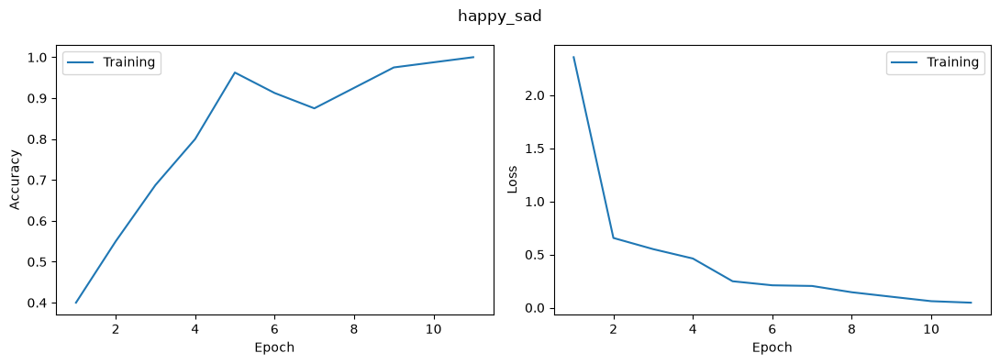

In [9]:
plot_history(history.history, 'happy_sad')

## Results

In [10]:
result = {'epochs': len(history.epoch), 'train_accuracy': history.history['accuracy'][-1],
          'threshold_reached': history.history['accuracy'][-1] >= 0.999}
display(pd.DataFrame([result]))
Path('results/happy_sad_metrics.json').write_text(json.dumps(result, indent=2))
pd.DataFrame(history.history).to_csv('results/happy_sad_history.csv', index=False)

,epochs,train_accuracy,threshold_reached
0,11,1.0,True


## Saving

In [3]:
model.save(MODEL_DIR / 'happy_sad.keras')
save_model(model, 'models/happy_sad')

In [ ]:
del model
keras.backend.clear_session()

# Cats and dogs

## Data

In [2]:
train_dir = DATA_ROOT / 'cats-dogs' / 'train'
validation_dir = DATA_ROOT / 'cats-dogs' / 'validation'
test_dir = DATA_ROOT / 'cats-dogs' / 'test'
classes = ['cat', 'dog']
split = pd.read_csv('../lab7/split.csv')
display(pd.crosstab(split['subset'], split['class']))

class,cat,dog
subset,,
test,500,500
train,1000,1000
validation,500,500


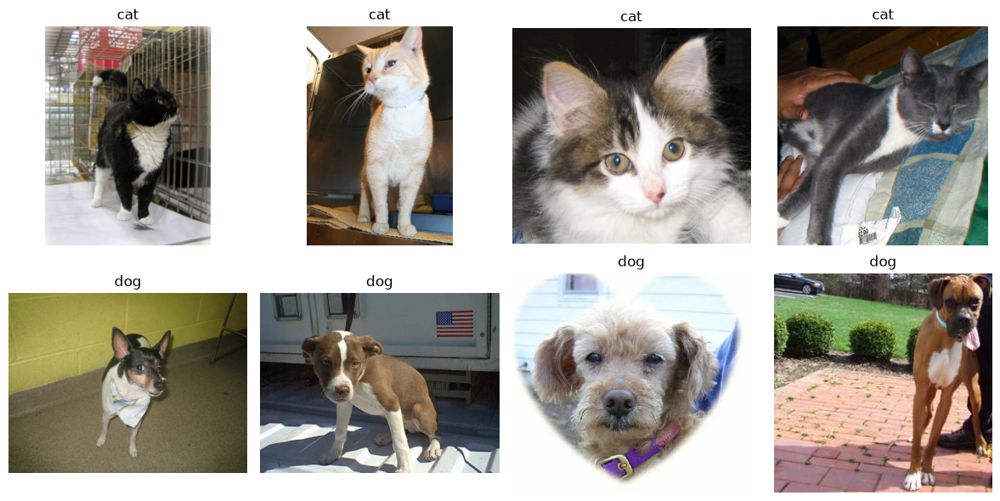

In [3]:
preview_images(train_dir, classes)

In [4]:
SIZE = 150
train_generator = make_generator(train_dir, classes, SIZE, shuffle=True)
validation_generator = make_generator(validation_dir, classes, SIZE)
test_generator = make_generator(test_dir, classes, SIZE)

Found 2000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


Found 1000 images belonging to 2 classes.


## Model

In [5]:
def build_cat_model(optimizer):
    model = keras.Sequential([layers.Input(shape=(150, 150, 3))])
    for filters in [32, 64, 128, 128]:
        model.add(layers.Conv2D(filters, 3, activation='relu'))
        model.add(layers.MaxPooling2D(2))
    model.add(layers.Flatten())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    opt = keras.optimizers.get(optimizer)
    opt.learning_rate = 0.001
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return model

configs = [{'name': 'adam', 'optimizer': 'adam'}, {'name': 'rmsprop', 'optimizer': 'rmsprop'}]
model = build_cat_model('adam')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

## Training

Epoch 1/20


63/63 - 21s - 330ms/step - accuracy: 0.5225 - loss: 0.6929 - val_accuracy: 0.5900 - val_loss: 0.6834


Epoch 2/20


63/63 - 4s - 69ms/step - accuracy: 0.5625 - loss: 0.6763 - val_accuracy: 0.5250 - val_loss: 0.6879


Epoch 3/20


63/63 - 5s - 74ms/step - accuracy: 0.6175 - loss: 0.6450 - val_accuracy: 0.6010 - val_loss: 0.6495


... (26 outputs left out)

Epoch 17/20


63/63 - 4s - 63ms/step - accuracy: 0.9100 - loss: 0.2230 - val_accuracy: 0.7850 - val_loss: 0.6161


Epoch 18/20


63/63 - 4s - 65ms/step - accuracy: 0.9140 - loss: 0.2053 - val_accuracy: 0.7630 - val_loss: 0.5751


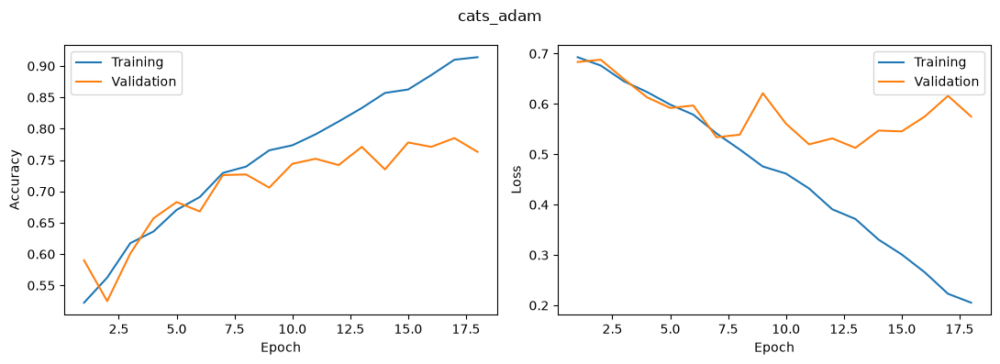

Epoch 1/20


63/63 - 11s - 170ms/step - accuracy: 0.5185 - loss: 0.6933 - val_accuracy: 0.5520 - val_loss: 0.6844


Epoch 2/20


63/63 - 4s - 63ms/step - accuracy: 0.5615 - loss: 0.6837 - val_accuracy: 0.5420 - val_loss: 0.6860


Epoch 3/20


63/63 - 4s - 66ms/step - accuracy: 0.6065 - loss: 0.6583 - val_accuracy: 0.5900 - val_loss: 0.6480


... (24 outputs left out)

Epoch 16/20


63/63 - 4s - 59ms/step - accuracy: 0.8810 - loss: 0.2702 - val_accuracy: 0.7550 - val_loss: 0.6211


Epoch 17/20


63/63 - 4s - 63ms/step - accuracy: 0.8910 - loss: 0.2434 - val_accuracy: 0.7760 - val_loss: 0.6045


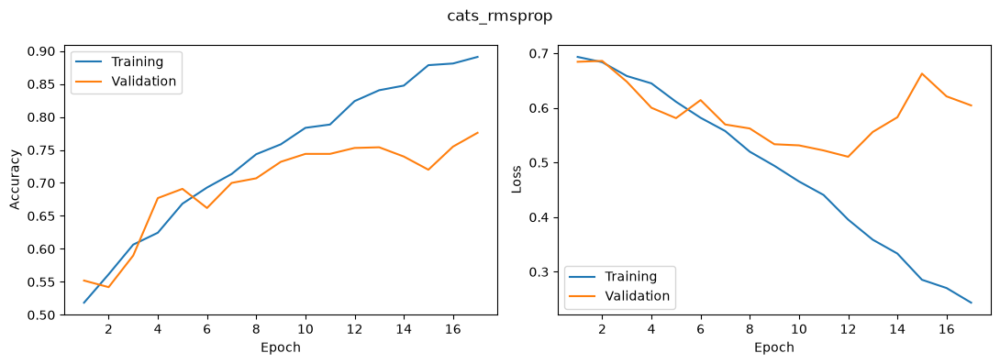

In [7]:
results = []
for config in configs:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    name = config['name']
    model = build_cat_model(config['optimizer'])
    train_generator.reset()
    start = time.perf_counter()
    history = model.fit(
        train_generator, validation_data=validation_generator, epochs=20, verbose=2,
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)])
    seconds = time.perf_counter() - start
    model.save(MODEL_DIR / f'cats_{name}.keras')
    val_loss, val_accuracy = model.evaluate(validation_generator, verbose=0)
    results.append({**config, 'epochs': len(history.epoch), 'seconds': seconds,
                    'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
                    'val_loss': val_loss, 'val_accuracy': val_accuracy,
                    'train_accuracy': history.history['accuracy'][-1]})
    pd.DataFrame(history.history).to_csv(f'results/cats_{name}_history.csv', index=False)
    plot_history(history.history, f'cats_{name}')

## Results

In [8]:
results = pd.DataFrame(results)
display(results)
results.to_csv('results/cats_experiments.csv', index=False)
best = results.sort_values('val_loss').iloc[0]
model = keras.models.load_model(MODEL_DIR / f"cats_{best['name']}.keras")
test_loss, test_accuracy = model.evaluate(test_generator, verbose=0)
result = {**best.to_dict(), 'test_loss': test_loss, 'test_accuracy': test_accuracy}
display(pd.DataFrame([result]))
Path('results/cats_metrics.json').write_text(json.dumps(result, indent=2))

,name,optimizer,epochs,seconds,best_epoch,val_loss,val_accuracy,train_accuracy
0,adam,adam,18,95.247494,13,0.512783,0.771,0.914
1,rmsprop,rmsprop,17,79.429219,12,0.510500,0.753,0.891


,name,optimizer,epochs,seconds,best_epoch,val_loss,val_accuracy,train_accuracy,test_loss,test_accuracy
0,rmsprop,rmsprop,17,79.429219,12,0.5105,0.753,0.891,0.488122,0.777


301

## Saving

In [3]:
model.save(MODEL_DIR / 'cats_best.keras')
save_model(model, 'models/cats_best')

## New images

In [10]:
SIZE = 150
NAME = 'cats'
def preprocess_input(images):
    return images / 255.0


image_dir = Path('../lab7/images')
manifest = pd.DataFrame(json.loads((image_dir / 'manifest.json').read_text()))
images = []
for filename in manifest['file']:
    image = keras.utils.load_img(image_dir / filename, target_size=(SIZE, SIZE))
    images.append(keras.utils.img_to_array(image))
images = np.array(images)

In [11]:
probabilities = model.predict(preprocess_input(images.copy()), batch_size=16, verbose=0).ravel()
new_results = manifest[['file', 'class']].copy()
new_results['dog_probability'] = probabilities
new_results['prediction'] = [classes[int(p >= 0.5)] for p in probabilities]
new_results['correct'] = new_results['class'] == new_results['prediction']
display(new_results)
print('External accuracy:', f"{new_results['correct'].mean():.2%}")
new_results.to_csv(f'results/{NAME}_external.csv', index=False)

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,0.534339,dog,False
1,cat_02.jpg,cat,0.926999,dog,False
2,cat_03.jpg,cat,0.998885,dog,False
3,cat_04.jpg,cat,0.282027,cat,True
4,cat_05.jpg,cat,0.996247,dog,False
5,dog_01.jpg,dog,0.740869,dog,True
6,dog_02.jpg,dog,0.971953,dog,True
7,dog_03.jpg,dog,0.411338,cat,False
8,dog_04.jpg,dog,0.209660,cat,False
9,dog_05.jpg,dog,0.208678,cat,False


External accuracy: 45.00%


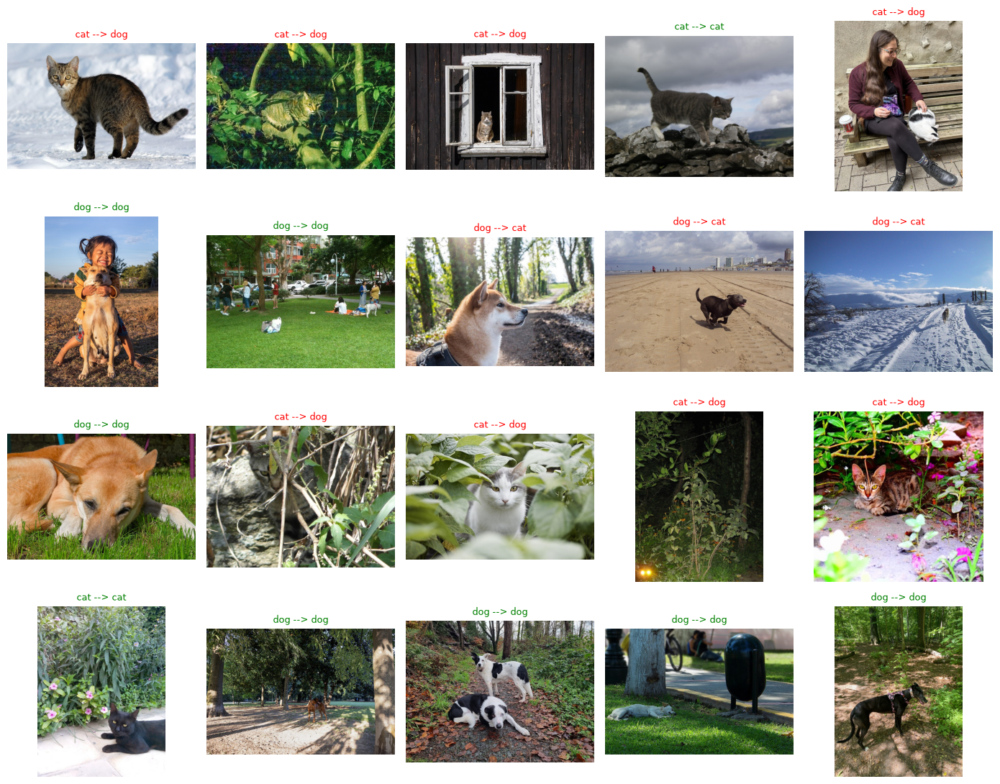

In [12]:
fig, axs = plt.subplots(4, 5, figsize=(14, 11))
for ax, row in zip(axs.flat, new_results.itertuples()):
    ax.imshow(Image.open(image_dir / row.file))
    ax.set_title(f'{row[2]} --> {row.prediction}', fontsize=9,
                 color='green' if row.correct else 'red')
    ax.axis('off')
plt.tight_layout()
fig.savefig(f'results/{NAME}_external.png', dpi=150)
plt.show()

## Cropped images

,file,class,dog_probability,prediction,correct
0,cat_01.jpg,cat,0.534339,dog,False
1,cat_02.jpg,cat,0.926999,dog,False
2,cat_03.jpg,cat,0.998885,dog,False
4,cat_05.jpg,cat,0.996247,dog,False
7,dog_03.jpg,dog,0.411338,cat,False
8,dog_04.jpg,dog,0.209660,cat,False


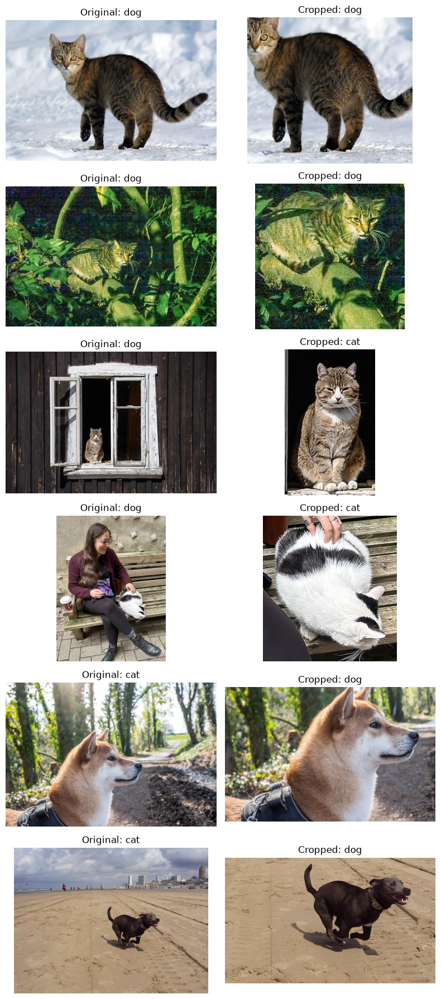

,file,class,before,after,dog_probability,correct_before,correct_after
0,cat_01.jpg,cat,dog,dog,0.587210,False,False
1,cat_02.jpg,cat,dog,dog,0.899371,False,False
2,cat_03.jpg,cat,dog,cat,0.074720,False,True
3,cat_05.jpg,cat,dog,cat,0.424990,False,True
4,dog_03.jpg,dog,cat,dog,0.844593,False,True
5,dog_04.jpg,dog,cat,dog,0.872998,False,True


In [3]:
# Use the first six errors as a separate diagnostic set, without selecting a model on them.
errors = new_results.loc[~new_results['correct']].head(6).copy()
display(errors)
crops = json.loads(Path('images/crops.json').read_text())
rows = []
fig, axs = plt.subplots(max(len(errors), 1), 2, figsize=(8, 3 * max(len(errors), 1)), squeeze=False)
for i, row in enumerate(errors.itertuples()):
    image = Image.open(image_dir / row.file).convert('RGB')
    box = crops[row.file]
    crop = image.crop(box)
    crop.save(f'images/cropped_{Path(row.file).stem}.png')
    array = np.array(crop.resize((SIZE, SIZE), Image.Resampling.NEAREST)).astype('float32')[None] / 255.0
    probability = float(model.predict(array, verbose=0)[0, 0])
    prediction = classes[int(probability >= 0.5)]
    rows.append({'file': row.file, 'class': row[2], 'before': row.prediction,
                 'after': prediction, 'dog_probability': probability,
                 'correct_before': row.correct, 'correct_after': prediction == row[2]})
    axs[i, 0].imshow(image)
    axs[i, 0].set_title(f'Original: {row.prediction}')
    axs[i, 1].imshow(crop)
    axs[i, 1].set_title(f'Cropped: {prediction}')
    for ax in axs[i]:
        ax.axis('off')
plt.tight_layout()
plt.show()
crop_results = pd.DataFrame(rows)
crop_results.to_csv('results/cats_crops.csv', index=False)
display(crop_results)

# Summary

У першій частині використано початкову архітектуру з п'ятьма згортковими блоками, RMSprop зі швидкістю 0.001 та 15 епох. Додано окремий валідаційний генератор, перевірку міток і кількості файлів та графіки навчання. У другій частині зменшено розмір входу і кількість блоків.

| Input | Blocks | Parameters | Training accuracy | Validation accuracy | Time (s) |
|---|---:|---:|---:|---:|---:|
| 300x300 | 5 | 1,704,097 | 97.18% | 75.39% | 106.7 |
| 150x150 | 3 | 9,494,561 | 100.00% | 82.42% | 84.8 |

Менший вхід пришвидшив цей запуск, але після видалення двох блоків збільшилася карта ознак перед Flatten, а отже й кількість параметрів Dense. Дослід одночасно змінює роздільність і глибину. Обидві мережі перенавчаються: висока навчальна точність не переноситься повністю на валідацію та реальні фотографії. На семи однозначно позначених зовнішніх фото отримано 3/7 для повторної моделі 300x300 і 5/7 для 150x150. Фото вершника з обома класами показано окремо.

Для Happy/Sad використано по 40 зображень двох класів. Callback зупинив навчання за 11 епох із точністю 100.00%, виконавши умову 99.9% раніше 15-ї епохи. Це навчальна точність, без окремої оцінки узагальнення.

Для Dogs vs. Cats скрипт створив поділ 2000/1000/1000 зображень зі збалансованими класами та перевіркою точних дублікатів. Порівняно Adam і RMSprop зі швидкістю 0.001. За валідаційними втратами обрано rmsprop: валідаційна точність 75.30%, тестова 77.70%. На 20 зовнішніх фото отримано 45.00%. Окремо відібрано шість помилок для досліду з обрізанням: після центрування тварини виправлено 4/6. Цей відібраний набір не є загальною оцінкою точності.

Моделі збережено для завантаження без навчання. Дані та повні контрольні точки залишено поза Git; до репозиторію включено архітектуру, навчені ваги, джерела зовнішніх фото та результати. Той самий поділ і ті самі зовнішні фото використовуються в лабораторних 8 і 9.